# Exploratory Data Analysis (EDA) of Hotel Booking Demand

**Student Name:** AKASH DATTA
**Dataset Name:** Hotel Booking Demand (`hotel_bookings.csv`)  
**Dataset Source:** [Kaggle — Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

## 1. Project Introduction

The dataset contains hotel booking records for a city hotel and a resort hotel. It includes booking status, lead time, arrival details, length of stay, guest counts, booking channels, room information, prices, and special requests.

### Objectives
- Understand the structure and quality of the dataset.
- Identify and handle duplicate records and missing values.
- Explore categorical and numerical variables using summary statistics and visualizations.
- Study patterns related to cancellations, lead time, hotel type, stay duration, and average daily rate (ADR).
- Examine relationships between variables and summarize actionable insights.

## 2. Load the Dataset

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

DATA_PATH = "hotel_bookings.csv"  # Keep the original dataset in the same folder and name it hotel_bookings.csv.
df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.tail())

Dataset loaded successfully.
Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.0,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


## 3. Understand the Dataset

In [3]:
print("Rows and columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nStatistical summary (numerical columns):")
display(df_raw.describe().T)

print("\nStatistical summary (categorical columns):")
display(df_raw.describe(include="object").T)

print("\nNumber of unique values per column:")
display(df_raw.nunique(dropna=False).sort_values().rename("unique_values").to_frame())

Rows and columns: (119390, 32)

Column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0



Statistical summary (categorical columns):


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613



Number of unique values per column:


,unique_values
hotel,2
is_canceled,2
is_repeated_guest,2
arrival_date_year,3
deposit_type,3
reservation_status,3
customer_type,4
babies,5
meal,5
distribution_channel,5


In [4]:
print("Missing values by column:")
missing_before = df_raw.isna().sum().sort_values(ascending=False)
display(missing_before[missing_before > 0].rename("missing_count").to_frame())

print("Exact duplicate rows:", int(df_raw.duplicated().sum()))

Missing values by column:


,missing_count
company,112593
agent,16340
country,488
children,4


Exact duplicate rows: 31994


**Initial observation:** The supplied dataset has booking-level records and a mixture of numeric and categorical fields. The checks above reveal the dataset dimensions, data types, missing-value concentration, and exact duplicate count. Missing values in `agent` and `company` are especially common and should be interpreted carefully because these fields identify booking intermediaries rather than measurements.

## 4. Check and Remove Duplicate Records

In [5]:
rows_before = len(df_raw)
duplicates_before = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().copy()
rows_after = len(df)
duplicates_after = int(df.duplicated().sum())

print(f"Rows before removal: {rows_before:,}")
print(f"Exact duplicate rows found: {duplicates_before:,}")
print(f"Rows after removal: {rows_after:,}")
print(f"Exact duplicate rows remaining: {duplicates_after:,}")

Rows before removal: 119,390
Exact duplicate rows found: 31,994
Rows after removal: 87,396
Exact duplicate rows remaining: 0


**Reasoning:** Exact duplicate rows are removed to reduce the risk of counting identical records more than once. This assumes that completely identical rows represent duplicate records; the notebook preserves all non-identical bookings.

## 5. Handle Missing Values

In [6]:
missing_pre_fill = df.isna().sum()
display(missing_pre_fill[missing_pre_fill > 0].sort_values(ascending=False).rename("missing_before").to_frame())

# Fill missing intermediary IDs with 0 as a documented 'not recorded / no intermediary ID' sentinel.
# Keep them numeric because the fields are identifiers.
for col in ["agent", "company"]:
    if col in df.columns:
        df[col] = df[col].fillna(0)

# A missing country is retained as an explicit category rather than deleting the booking.
if "country" in df.columns:
    df["country"] = df["country"].fillna("Unknown")

# Only four child values are missing in this supplied dataset; use 0 for the guest count.
if "children" in df.columns:
    df["children"] = df["children"].fillna(0)

missing_after_fill = df.isna().sum()
print("Missing values remaining:", int(missing_after_fill.sum()))
display(missing_after_fill[missing_after_fill > 0].rename("missing_after").to_frame())

,missing_before
company,82137
agent,12193
country,452
children,4


Missing values remaining: 0


,missing_after


**Missing-value decisions**
- `agent` and `company`: missing IDs are filled with `0`, used here as a sentinel for “no ID recorded”; it is not treated as a real agent/company ID.
- `country`: filled with `Unknown` so the booking remains in the dataset and missingness is visible in categorical analysis.
- `children`: filled with `0` because only a very small number of guest-count entries are missing and zero is a plausible count. This assumption should be disclosed.
- No rows are dropped solely because of missing values.

## 6. Clean the Dataset

In [7]:
# Strip leading/trailing spaces from text fields and standardize blank strings.
text_cols = df.select_dtypes(include=["object"]).columns
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Convert reservation status date to datetime. Invalid values become NaT.
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"], errors="coerce")

# Convert numeric columns to numeric types if any imported as text.
numeric_candidates = [
    "is_canceled", "lead_time", "arrival_date_year", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes", "agent", "company",
    "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Refill values affected by numeric conversion using the documented policies.
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

# Validate key binary fields and flag unexpected values instead of silently changing them.
print("is_canceled values:", sorted(df["is_canceled"].dropna().unique().tolist()))
print("is_repeated_guest values:", sorted(df["is_repeated_guest"].dropna().unique().tolist()))
print("Reservation status values:", df["reservation_status"].value_counts(dropna=False).to_dict())
print("Shape after cleaning:", df.shape)
print("Missing cells after cleaning:", int(df.isna().sum().sum()))

is_canceled values: [0, 1]
is_repeated_guest values: [0, 1]
Reservation status values: {'Check-Out': 63371, 'Canceled': 23011, 'No-Show': 1014}
Shape after cleaning: (87396, 32)
Missing cells after cleaning: 0


**Cleaning notes:** Text whitespace is standardized, numeric fields are converted where appropriate, and the reservation-status date is parsed as a date. Identifier fields (`agent`, `company`) remain numeric but the sentinel value `0` means “not recorded.” The dataset's month names and category labels are retained rather than arbitrarily re-mapped. Invalid values are checked and reported instead of silently changing their meaning.

## 7. Analyze Categorical Columns

In [8]:
categorical_cols = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print("Categorical columns:", categorical_cols)

for col in ["hotel", "meal", "market_segment", "distribution_channel", "customer_type", "deposit_type", "reservation_status"]:
    if col in df.columns:
        print(f"\n{col} — category counts (top 15):")
        display(df[col].value_counts(dropna=False).head(15).rename("count").to_frame())

Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status']

hotel — category counts (top 15):


,count
hotel,
City Hotel,53428
Resort Hotel,33968



meal — category counts (top 15):


,count
meal,
BB,67978
SC,9481
HB,9085
Undefined,492
FB,360



market_segment — category counts (top 15):


...

,count
customer_type,
Transient,71986
Transient-Party,11727
Contract,3139
Group,544



deposit_type — category counts (top 15):


,count
deposit_type,
No Deposit,86251
Non Refund,1038
Refundable,107



reservation_status — category counts (top 15):


,count
reservation_status,
Check-Out,63371
Canceled,23011
No-Show,1014


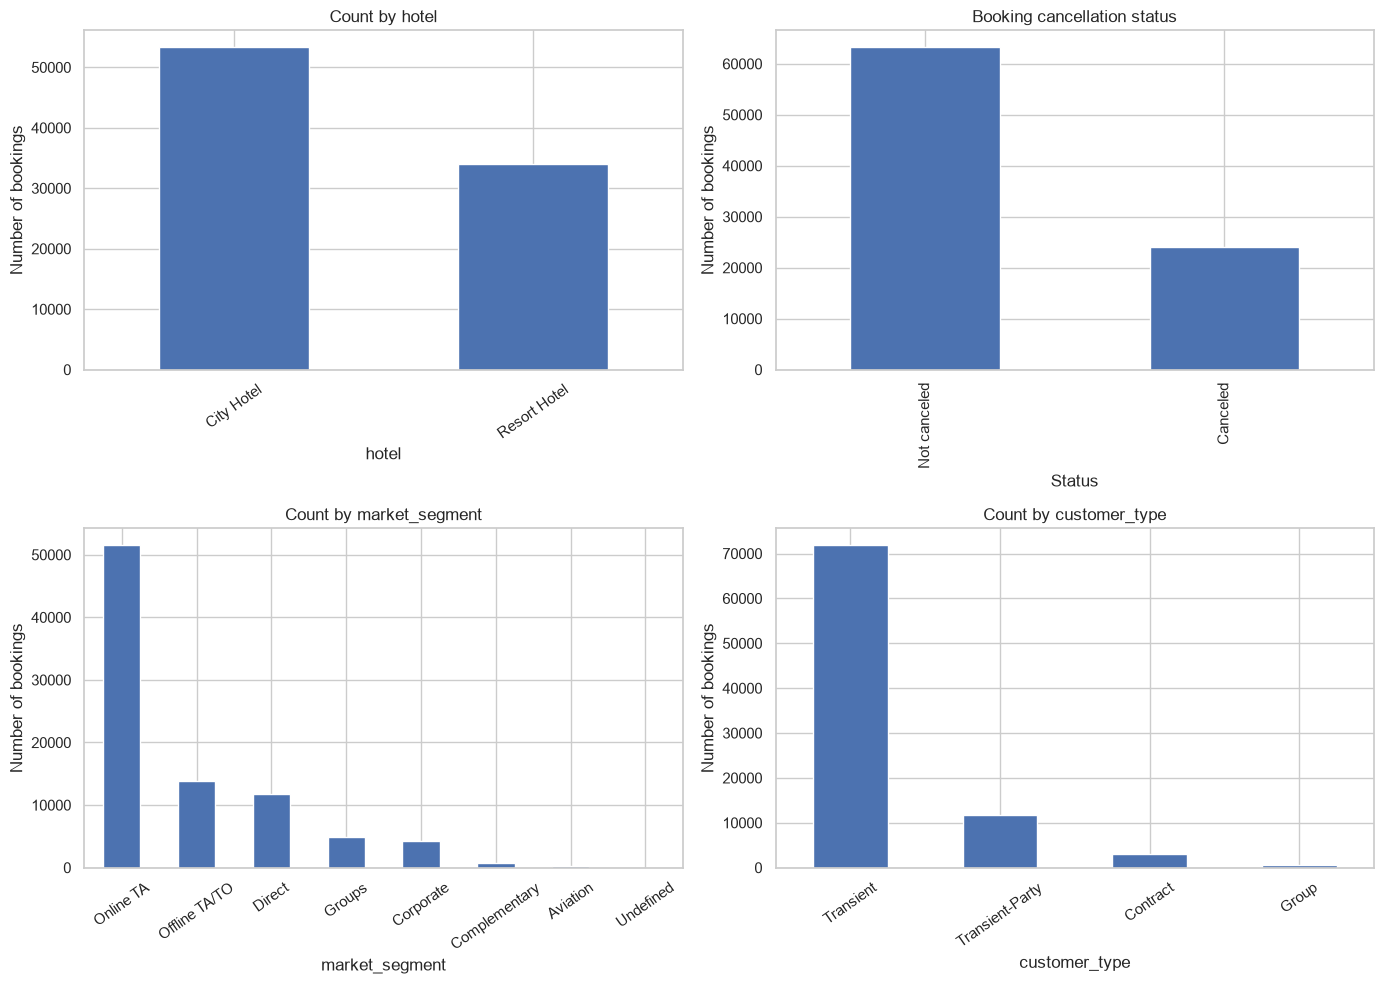

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_cols = ["hotel", "is_canceled", "market_segment", "customer_type"]
for ax, col in zip(axes.flat, plot_cols):
    if col == "is_canceled":
        labels = df[col].map({0: "Not canceled", 1: "Canceled"}).fillna("Unknown")
        labels.value_counts().plot(kind="bar", ax=ax)
        ax.set_title("Booking cancellation status")
        ax.set_xlabel("Status")
    else:
        order = df[col].value_counts().head(10).index
        df[col].value_counts().reindex(order).plot(kind="bar", ax=ax)
        ax.set_title(f"Count by {col}")
        ax.tick_params(axis="x", rotation=35)
    ax.set_ylabel("Number of bookings")
plt.tight_layout()
plt.show()

**Observation:** The charts compare booking volumes across hotel type, cancellation status, market segment, and customer type. The frequency tables above provide exact category counts; the most frequent categories indicate where the dataset's records are concentrated. These are booking counts, not necessarily unique customers.

## 8. Analyze Numerical Columns

,mean,median,min,max,std
is_canceled,0.274898,0.0,0.00,1.0,0.446466
lead_time,79.891368,49.0,0.00,737.0,86.052325
arrival_date_year,2016.210296,2016.0,2015.00,2017.0,0.686102
arrival_date_week_number,26.838334,27.0,1.00,53.0,13.674572
arrival_date_day_of_month,15.815541,16.0,1.00,31.0,8.835146
stays_in_weekend_nights,1.005263,1.0,0.00,19.0,1.031921
stays_in_week_nights,2.625395,2.0,0.00,50.0,2.053584
adults,1.875795,2.0,0.00,55.0,0.626500
children,0.138633,0.0,0.00,10.0,0.455871
babies,0.010824,0.0,0.00,10.0,0.113597


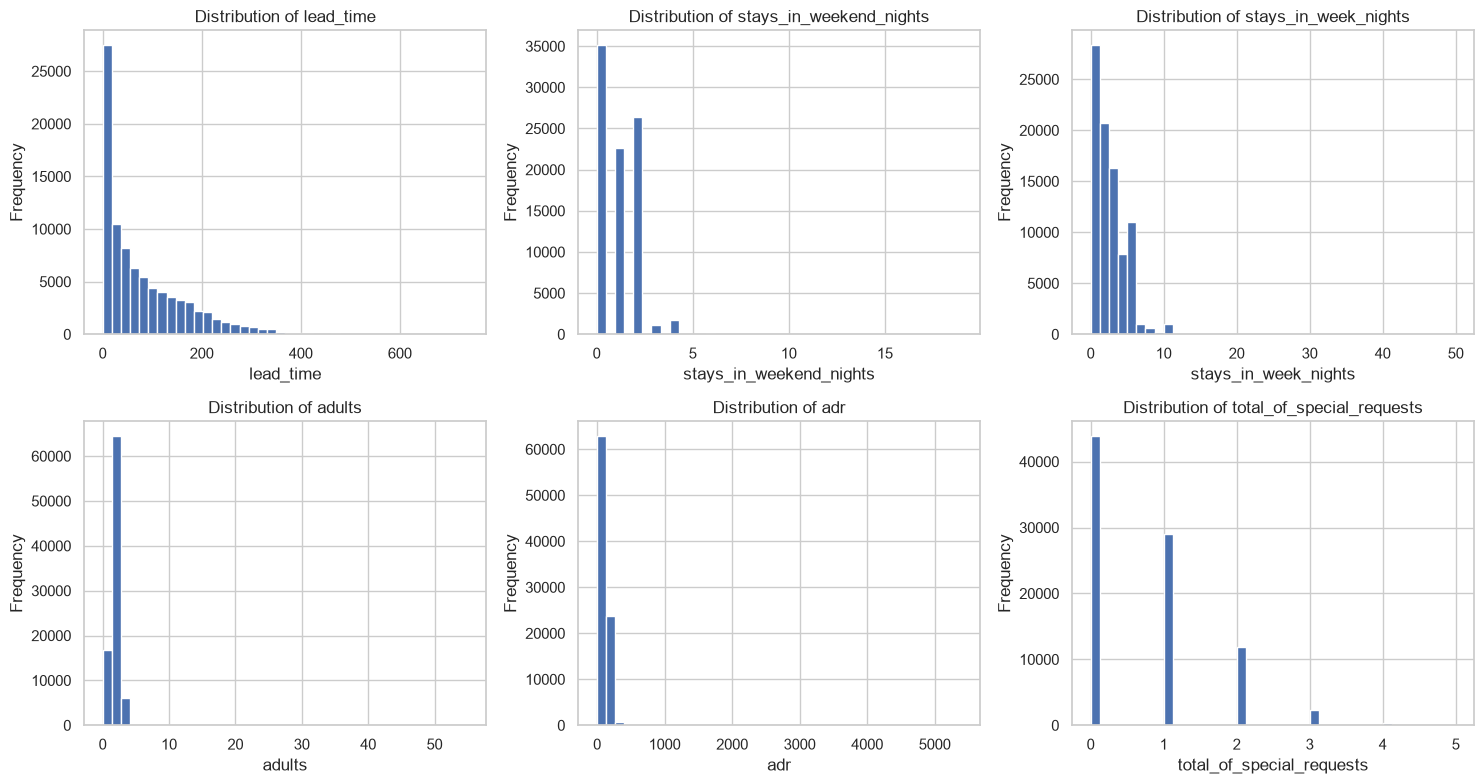

In [10]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T[["mean", "50%", "min", "max", "std"]].rename(columns={"50%": "median"}))

# Distribution plots for selected interpretable numeric variables.
selected_num = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "adr", "total_of_special_requests"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, selected_num):
    df[col].dropna().plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Observation:** Use the median alongside the mean because booking variables such as lead time and ADR can be skewed by a smaller number of high values. The histograms show whether values cluster near zero or have a long right tail. ADR is the average daily rate recorded for a booking; values should be interpreted in the dataset's original currency context.

## 9. Detect and Handle Outliers

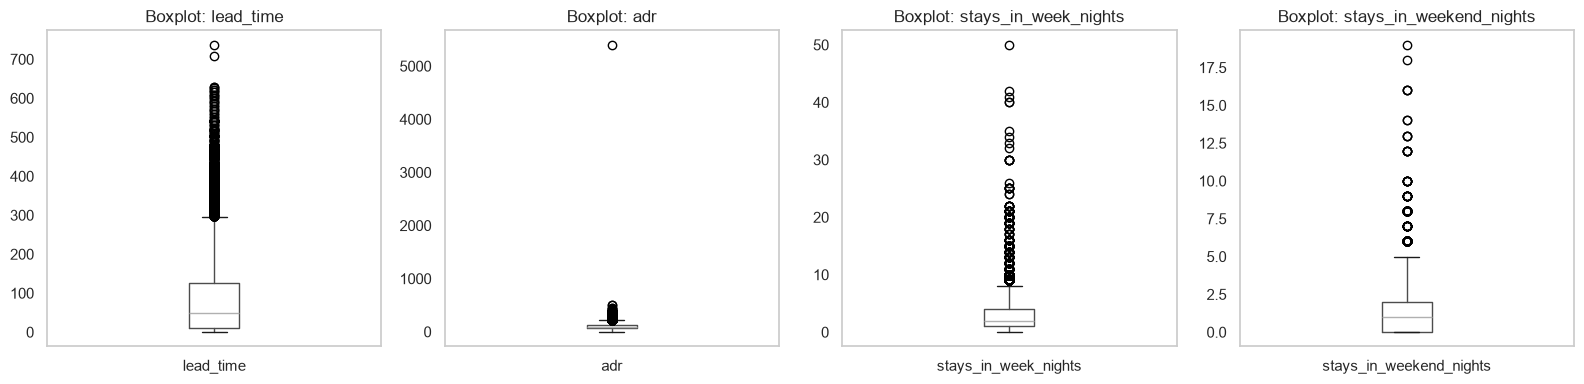

,column,Q1,Q3,IQR,lower_fence,upper_fence,IQR_outlier_count
0,lead_time,11.0,125.0,114.0,-160.0,296.0,2396
1,adr,72.0,134.0,62.0,-21.0,227.0,2490
2,stays_in_week_nights,1.0,4.0,3.0,-3.5,8.5,1531
3,stays_in_weekend_nights,0.0,2.0,2.0,-3.0,5.0,220


In [11]:
outlier_cols = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights"]
outlier_summary = []
fig, axes = plt.subplots(1, len(outlier_cols), figsize=(16, 4))
for ax, col in zip(axes, outlier_cols):
    df.boxplot(column=col, ax=ax, grid=False)
    ax.set_title(f"Boxplot: {col}")
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    outlier_summary.append({"column": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                            "lower_fence": low, "upper_fence": high, "IQR_outlier_count": n_out})
plt.tight_layout()
plt.show()
display(pd.DataFrame(outlier_summary))

**Outlier decision:** No observations are automatically deleted or winsorized solely because they fall outside the 1.5×IQR fences. Long lead times, longer stays, and high/low rates can be genuine bookings, while zero or negative ADR may need business-context review. Retaining these values avoids erasing potentially meaningful cases; any later model should validate extreme values and consider robust methods if needed.

## 10. Univariate Analysis

In [12]:
# One-variable summaries: cancellation rate, hotel distribution, lead time, ADR, and stay duration.
cancellation_rate = df["is_canceled"].mean() * 100
print(f"Cancellation rate among retained records: {cancellation_rate:.2f}%")
print("\nHotel booking counts:")
display(df["hotel"].value_counts().rename("bookings").to_frame())
print("\nLead-time quantiles:")
display(df["lead_time"].quantile([0, .25, .5, .75, .9, .95, .99, 1]).rename("lead_time").to_frame())
print("\nADR quantiles:")
display(df["adr"].quantile([0, .25, .5, .75, .9, .95, .99, 1]).rename("adr").to_frame())
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
print("\nTotal nights summary:")
display(df["total_nights"].describe().to_frame())

Cancellation rate among retained records: 27.49%

Hotel booking counts:


,bookings
hotel,
City Hotel,53428
Resort Hotel,33968



Lead-time quantiles:


,lead_time
0.00,0.0
0.25,11.0
0.50,49.0
0.75,125.0
0.90,204.0
0.95,256.0
0.99,347.0
1.00,737.0



ADR quantiles:


,adr
0.00,-6.380
0.25,72.000
0.50,98.100
0.75,134.000
0.90,174.000
0.95,204.000
0.99,261.405
1.00,5400.000



Total nights summary:


,total_nights
count,87396.000000
mean,3.630658
std,2.763449
min,0.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,69.000000


## 11. Bivariate Analysis

Cancellation rate by hotel (%):


,cancellation_rate_percent
hotel,
City Hotel,30.038557
Resort Hotel,23.480923


Cancellation rate by market segment (%):


,cancellation_rate_percent
market_segment,
Undefined,100.000000
Online TA,35.346197
Groups,27.013355
Aviation,19.823789
Offline TA/TO,14.853481
Direct,14.715351
Complementary,12.535613
Corporate,12.108262


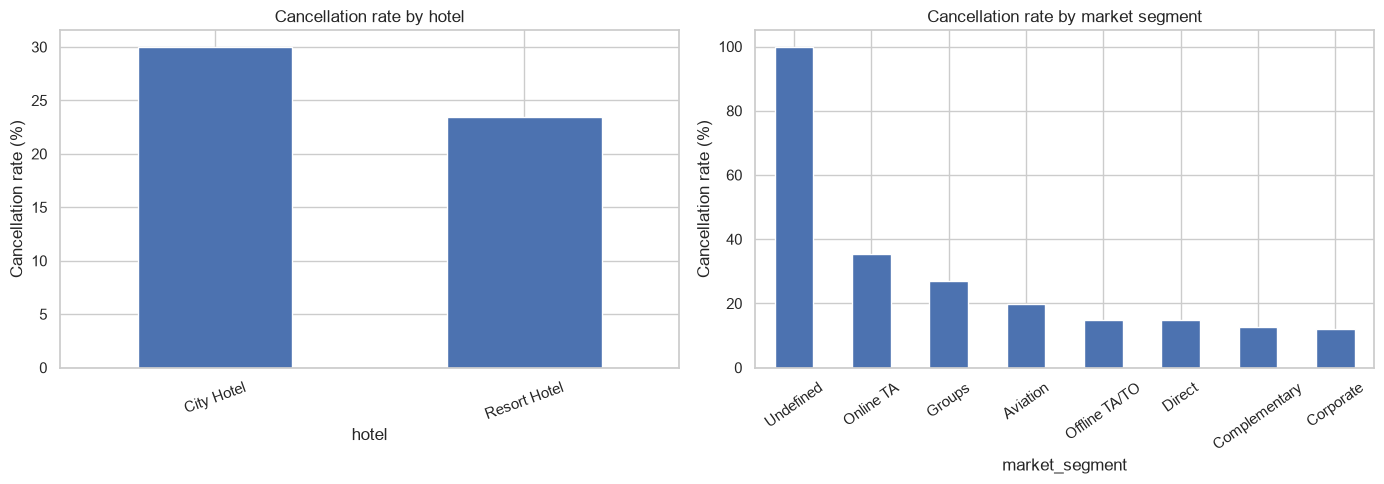

In [13]:
# Cancellation rate by hotel and market segment
cancel_by_hotel = df.groupby("hotel", dropna=False)["is_canceled"].mean().mul(100).sort_values(ascending=False)
cancel_by_segment = df.groupby("market_segment", dropna=False)["is_canceled"].mean().mul(100).sort_values(ascending=False)
print("Cancellation rate by hotel (%):")
display(cancel_by_hotel.rename("cancellation_rate_percent").to_frame())
print("Cancellation rate by market segment (%):")
display(cancel_by_segment.rename("cancellation_rate_percent").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cancel_by_hotel.plot(kind="bar", ax=axes[0])
axes[0].set_title("Cancellation rate by hotel")
axes[0].set_ylabel("Cancellation rate (%)")
axes[0].tick_params(axis="x", rotation=20)
cancel_by_segment.plot(kind="bar", ax=axes[1])
axes[1].set_title("Cancellation rate by market segment")
axes[1].set_ylabel("Cancellation rate (%)")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

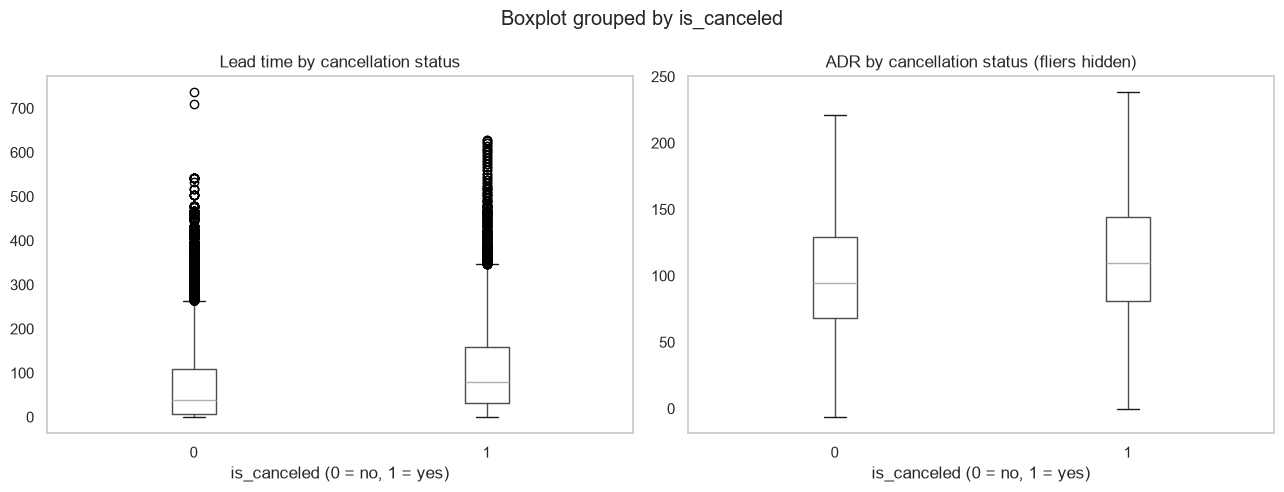

In [14]:
# Lead time and ADR distributions by cancellation status (sample for readability).
sample_df = df[["is_canceled", "lead_time", "adr"]].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sample_df.boxplot(column="lead_time", by="is_canceled", ax=axes[0], grid=False)
axes[0].set_title("Lead time by cancellation status")
axes[0].set_xlabel("is_canceled (0 = no, 1 = yes)")
sample_df.boxplot(column="adr", by="is_canceled", ax=axes[1], showfliers=False, grid=False)
axes[1].set_title("ADR by cancellation status (fliers hidden)")
axes[1].set_xlabel("is_canceled (0 = no, 1 = yes)")
plt.tight_layout()
plt.show()

**Observation:** These comparisons test whether cancellation frequency differs by hotel or market segment and whether lead time and ADR distributions differ between canceled and non-canceled bookings. Group differences are associations in this dataset; they do not prove that a variable causes cancellation.

## 12. Multivariate Analysis

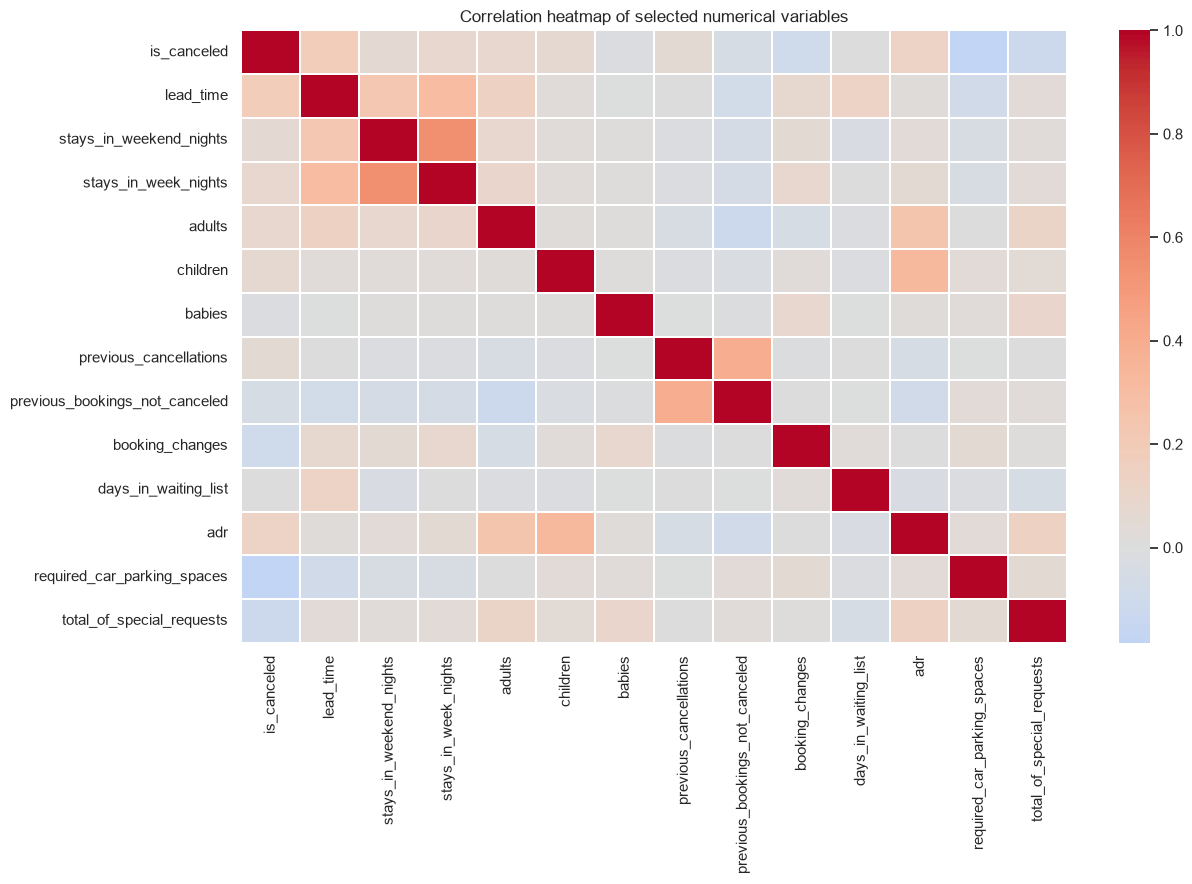

Strongest absolute correlations (excluding self-correlations):


correlation  absolute_correlation
stays_in_weekend_nights stays_in_week_nights               0.555552              0.555552
previous_cancellations  previous_bookings_not_canceled     0.392064              0.392064
children                adr                                0.326293              0.326293
lead_time               stays_in_week_nights               0.310129              0.310129
adults                  adr                                0.248999              0.248999
lead_time               stays_in_weekend_nights            0.235145              0.235145
is_canceled             lead_time                          0.184806              0.184806
                        required_car_parking_spaces       -0.184206              0.184206
lead_time               adults                             0.140493              0.140493
adr                     total_of_special_requests          0.137831              0.137831
lead_time               days_in_waiting_list               0.132152              0.132152
is_canceled             adr                                0.127986              0.127986

In [15]:
# Correlation among numeric fields. Identifiers are excluded because numeric IDs are not measurements.
correlation_cols = [
    "is_canceled", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes", "days_in_waiting_list",
    "adr", "required_car_parking_spaces", "total_of_special_requests"
]
corr = df[correlation_cols].corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
plt.title("Correlation heatmap of selected numerical variables")
plt.tight_layout()
plt.show()

print("Strongest absolute correlations (excluding self-correlations):")
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("correlation").to_frame()
corr_pairs["absolute_correlation"] = corr_pairs["correlation"].abs()
display(corr_pairs.sort_values("absolute_correlation", ascending=False).head(12))

hotel,City Hotel,Resort Hotel
customer_type,,
Contract,25.02,8.63
Group,8.86,10.99
Transient,32.42,26.32
Transient-Party,16.79,12.90


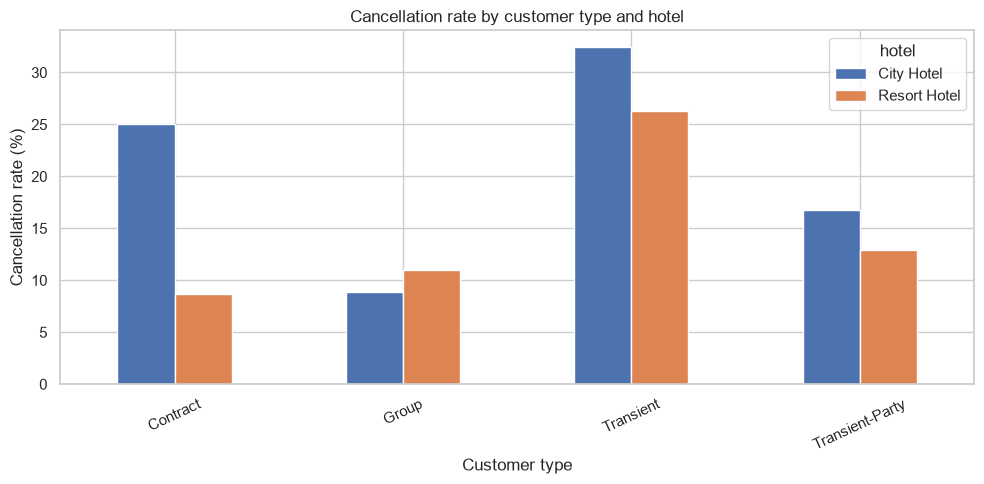

In [16]:
# Multivariable comparison: cancellation rate by hotel and customer type
pivot_cancel = pd.pivot_table(
    df, values="is_canceled", index="customer_type", columns="hotel",
    aggfunc="mean", observed=False
) * 100
display(pivot_cancel.round(2))
pivot_cancel.plot(kind="bar", figsize=(10, 5))
plt.title("Cancellation rate by customer type and hotel")
plt.ylabel("Cancellation rate (%)")
plt.xlabel("Customer type")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**Observation:** The heatmap summarizes linear associations among selected numeric variables. Correlation does not imply causation, and the correlation of an identifier with another variable should not be interpreted as meaningful. The grouped cancellation chart adds context by comparing customer types within each hotel.

## 13. Key Insights

In [17]:
# Compute data-grounded insight values to avoid hard-coded claims.
hotel_counts = df["hotel"].value_counts()
hotel_share = hotel_counts / len(df) * 100
segment_counts = df["market_segment"].value_counts()
cancel_rates_hotel = df.groupby("hotel")["is_canceled"].mean() * 100
cancel_rates_segment = df.groupby("market_segment")["is_canceled"].mean() * 100
lead_median_by_cancel = df.groupby("is_canceled")["lead_time"].median()
adr_median_by_cancel = df.groupby("is_canceled")["adr"].median()
total_nights_median = df["total_nights"].median()
top_country = df["country"].value_counts().head(1)
special_request_median = df["total_of_special_requests"].median()

print("Key insights from the cleaned dataset:")
print(f"1. The cleaned dataset contains {len(df):,} records and {df.shape[1]} columns.")
print(f"2. {hotel_counts.index[0]} is the most represented hotel type ({hotel_share.iloc[0]:.1f}% of records).")
print(f"3. Overall cancellation rate is {df['is_canceled'].mean()*100:.1f}%.")
print(f"4. Cancellation rate differs by hotel: {cancel_rates_hotel.idxmax()} is higher at {cancel_rates_hotel.max():.1f}% versus {cancel_rates_hotel.min():.1f}% for {cancel_rates_hotel.idxmin()}.")
print(f"5. The most frequent market segment is {segment_counts.index[0]} ({segment_counts.iloc[0]:,} records).")
print(f"6. Median lead time is {lead_median_by_cancel.get(1, np.nan):.0f} days for canceled bookings and {lead_median_by_cancel.get(0, np.nan):.0f} days for non-canceled bookings.")
print(f"7. Median ADR is {adr_median_by_cancel.get(1, np.nan):.2f} for canceled bookings and {adr_median_by_cancel.get(0, np.nan):.2f} for non-canceled bookings.")
print(f"8. Median total stay length is {total_nights_median:.0f} night(s).")
print(f"9. The most common country code is {top_country.index[0]} ({top_country.iloc[0]:,} records), including Unknown only if it is most frequent.")
print(f"10. Median number of special requests is {special_request_median:.0f}.")

Key insights from the cleaned dataset:
1. The cleaned dataset contains 87,396 records and 33 columns.
2. City Hotel is the most represented hotel type (61.1% of records).
3. Overall cancellation rate is 27.5%.
4. Cancellation rate differs by hotel: City Hotel is higher at 30.0% versus 23.5% for Resort Hotel.
5. The most frequent market segment is Online TA (51,618 records).
6. Median lead time is 80 days for canceled bookings and 38 days for non-canceled bookings.
7. Median ADR is 109.80 for canceled bookings and 94.50 for non-canceled bookings.
8. Median total stay length is 3 night(s).
9. The most common country code is PRT (27,453 records), including Unknown only if it is most frequent.
10. Median number of special requests is 0.


## 14. Final Conclusion

This project followed a complete EDA workflow: loading and inspecting the hotel booking data, removing exact duplicates, handling missing values, cleaning data types and text fields, analyzing categorical and numerical columns, checking potential outliers, and studying univariate, bivariate, and multivariate patterns.

The dataset can support future machine-learning work such as predicting booking cancellation. For a valid predictive model, define the prediction point carefully and avoid data leakage: fields recorded after the booking outcome (for example, `reservation_status` and `reservation_status_date`) should not be used as predictors if the goal is to predict cancellation in advance. Use a train/test split, evaluate class balance, and report suitable metrics such as precision, recall, F1-score, and ROC-AUC.

### Data-quality limitations
- Exact duplicate rows were removed; identical rows are assumed to be duplicated records.
- Missing `agent` and `company` IDs were represented by `0`, and missing country values by `Unknown`.
- The four missing child-count values were filled with `0` under an explicit assumption.
- Potential outliers were retained because IQR flags alone do not prove a value is erroneous.
- The dataset is observational; discovered relationships should not be described as causal.

## 15. Final Cleaned DataFrame

In [18]:
# Keep total_nights as a useful derived feature and provide the final cleaned dataframe.
df_clean = df.copy()
print("Final cleaned dataset shape:", df_clean.shape)
print("Missing cells:", int(df_clean.isna().sum().sum()))
print("Exact duplicate rows:", int(df_clean.duplicated().sum()))
display(df_clean.head())

Final cleaned dataset shape: (87396, 33)
Missing cells: 0
Exact duplicate rows: 0


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,2


## Save the Cleaned CSV

Run this cell to write the final cleaned dataset next to the notebook. If submitting from a local Jupyter environment, make sure the source CSV path in Section 2 points to your downloaded file.

In [19]:
df_clean.to_csv("Hotel_Booking_Cleaned.csv", index=False)
print("Saved: Hotel_Booking_Cleaned.csv")

Saved: Hotel_Booking_Cleaned.csv


## Dataset Reference
- Kaggle: [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)
- Supplied input file: `hotel_bookings(4).csv`

